# Lab 10 — The end-to-end project

*Take one model from the question to a watched service*

**Goal.** Work through a whole project on real hotel bookings: check the data against a contract, validate the way the model will be used, keep an experiment log, choose a model by a rule fixed in advance, open the test quarter once, ship the model with one command, tests, a web service and a page for people, and then watch it through five months of new bookings.

**Data.** `all_datasets/supervised/hotel_bookings/hotel_bookings.zip` with its data card `README.md`

**Run.** From the course folder, start `jupyter lab`, open `all_experiments/lab10_end_to_end_project/lab10_end_to_end_project_worked.ipynb`, and choose **Restart Kernel and Run All Cells**. The same code runs as a script: `python all_experiments/lab10_end_to_end_project/lab10_end_to_end_project_worked.py`.

**Evidence.** `results/lab10/` — the monthly cancellation rates, the experiment log, the test-quarter report by group, the calibration table, the monthly monitoring report, the call-list results, the retraining comparison and the run log; `models/` — the champion with its card

**Your map of this lab**

| Part | What you do | Questions |
| --- | --- | --- |
| A | Read the bookings over time, check them against the contract, and find the columns written too late | 2–5 |
| B | Cut three periods, compare random and forward validation, find the repeated blocks, set baselines | 6–9 |
| C | Keep an experiment log, choose by a rule, open the test quarter once, write the card | 10–13 |
| D | Ship: one command, tests, a web service and a page for people | 14–17 |
| E | Watch five months: drift, the right reference, the call list, retraining | 18–21 |
| Finish | Save the evidence; then correct the monthly forecast yourself | 22–24 |
| After | Your-turn tasks, expected findings, troubleshooting and the checklist (on the lab sheet) | — |

## Setup

### Question 1 — Setup

Run this first, and keep this kernel for the later questions. This lab has one step more than the others: the project of Chapters 32 and 33 lives in the folder `booking_project/` beside this notebook, and the lab imports it like any library. Open `booking_project/bookings.py` in an editor now; most questions use something from it.

**Read the code.**

- The second `sys.path.insert` lets Python import the files of `booking_project/`. `import bookings as project` makes its contract, features and models available as `project.CONTRACT`, `project.FEATURES`, `project.logistic` and so on.
- `monitor`, `serve` and `train` are the project's other files. Each line imports the one or two functions the lab needs from them.
- `subprocess` runs a command as if it were typed in a terminal, which is how Part D runs the project's scripts.

In [1]:
# 1. The course helper: finds the course folder and prepares the output folders.
import sys
sys.path.insert(0, "..")                     # all_experiments/, where course_setup.py lives
from course_setup import start_lab

# 2. The project of Chapters 32 and 33, in booking_project/: imported like any library.
sys.path.insert(0, "booking_project")
import bookings as project                   # the contract, the features and the models
from monitor import monthly_report, psi      # drift and monthly reports
from serve import create_app                 # the web service
from train import train                      # fit on every booking before a date, with a gate

# 3. The other libraries this lab uses.
import json
import subprocess                            # run a command, as you would in a terminal
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 4. Where this lab reads and writes.
DATA, RESULTS, MODELS = start_lab("lab10")

course folder: MACHINE LEARNING
reads all_datasets/, writes results/lab10/ and models/


## Part A — The data, the contract and the clock

**Goal.** Read the bookings in date order, check the hotel's file against the project's contract, look behind every finding, and find the columns that are written too late to use.

*Questions 2–5 · Data: hotel bookings and their data card*

### Question 2 — Read the bookings in date order

The model will be asked on the first day of each month about the bookings arriving that month, so time runs through the whole project. Read the bookings with the project's own function, which builds the arrival date, sorts by it and adds the features, and then look at the share cancelled quarter by quarter and month by month.

**Read the code.**

- `project.read_bookings(FILE)` is the function that `train.py` also uses, so the lab and the shipped model read the file in exactly the same way.
- `f"{date:%d %B %Y}"` prints a date as day, month name and year.
- `bookings["arrival_date"].dt.to_period("Q")` gives each booking its quarter of arrival, such as `2016Q3`, and `dt.to_period("M")` its month.
- `groupby(quarter)["is_canceled"].agg(bookings="size", cancelled="mean")` counts the bookings of each quarter and computes the share cancelled, under the two names given.
- `map("{:,}".format)` writes each count as text with a thousands separator, and `"{:.1%}"` writes each share as a percentage. `.T` turns the table on its side so that the quarters run across.
- `ax.axvspan(start, end, ...)` shades a stretch of the horizontal axis. Here it marks the test quarter and the live months.

119,390 bookings arriving from 01 July 2015 to 31 August 2017
arrival_date  2015Q3  2015Q4  2016Q1  2016Q2  2016Q3  2016Q4  2017Q1  2017Q2  2017Q3
bookings      11,779  10,217  10,963  16,198  15,029  14,517  12,828  17,621  10,238
cancelled      42.0%   31.2%   30.7%   37.5%   35.6%   38.2%   33.4%   43.5%   37.1%


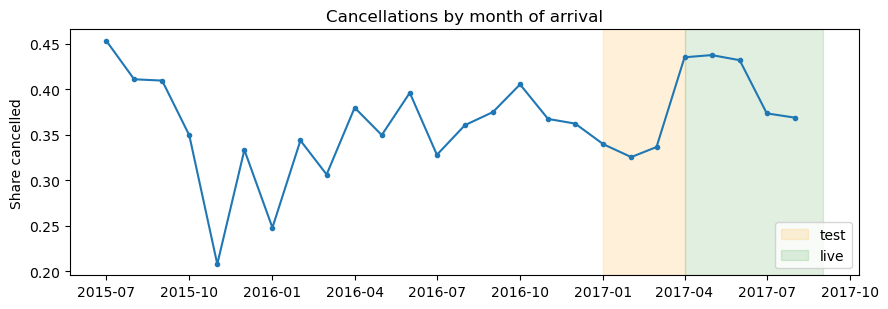

In [2]:
FILE = DATA / "supervised/hotel_bookings/hotel_bookings.zip"
bookings = project.read_bookings(FILE)
y = bookings["is_canceled"]
print(f"{len(bookings):,} bookings arriving from {bookings['arrival_date'].min():%d %B %Y}"
      f" to {bookings['arrival_date'].max():%d %B %Y}")

quarter = bookings["arrival_date"].dt.to_period("Q")
month = bookings["arrival_date"].dt.to_period("M")
by_quarter = bookings.groupby(quarter)["is_canceled"].agg(bookings="size", cancelled="mean")
print(pd.DataFrame({"bookings": by_quarter["bookings"].map("{:,}".format),
                    "cancelled": by_quarter["cancelled"].map("{:.1%}".format)}).T.to_string())

monthly_rate = bookings.groupby(month)["is_canceled"].mean()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(monthly_rate.index.to_timestamp(), monthly_rate.to_numpy(), marker="o", markersize=3)
start, test_end, live_end = (pd.Timestamp(day) for day in ["2017-01-01", "2017-04-01", "2017-09-01"])
ax.axvspan(start, test_end, color="orange", alpha=0.15, label="test")
ax.axvspan(test_end, live_end, color="green", alpha=0.12, label="live")
ax.set_ylabel("Share cancelled")
ax.set_title("Cancellations by month of arrival")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS / "cancellations_by_month_of_arrival.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** <!-- figure: cancellations_by_month_of_arrival.png | Cancellations by month of arrival | 4.6cm -->
119,390 bookings over 26 months. The share cancelled moves in two ways at once. It follows the season: the two winter quarters are the lowest, with 31.2% and 30.7% cancelled. And it rises from one year to the next: 43.5% of the bookings arriving in the second quarter of 2017 were cancelled, against 37.5% a year earlier. A model trained on 2015 and 2016 expects the past's rate, so expect it to count too few cancellations in 2017. Part E measures by how much.

### Question 3 — Check the file against the contract

The contract in `bookings.py` says what each column may hold. Run the check on the hotel's raw file, then look behind every finding before deciding anything: a finding can be a mistake in the data or a mistake in the contract.

**Read the code.**

- `project.validate(raw)` returns one line per problem, and an empty list when the file passes.
- `raw[raw["adults"] > 10]` keeps the bookings behind the first finding. The `print` summarizes them in one line: how many, which hotel, which months, which prices, and the share cancelled.
- `raw["adr"].between(0, 1000)` is true for prices inside the contract, so `~` picks the two outside it. `raw.loc[raw["adr"] < 1000, "adr"].max()` is the highest price below 1,000.
- The last lines count the bookings with no guests at all, which the contract does not yet check.

In [3]:
raw = pd.read_csv(FILE)
problems = project.validate(raw)
for line in problems:
    print(line)

big = raw[raw["adults"] > 10]
months_of_arrival = sorted(set(big["arrival_date_month"] + " " + big["arrival_date_year"].astype(str)))
print(f"\nmore than 10 adults: {len(big)} bookings at {big['hotel'].unique().tolist()},"
      f" arriving {months_of_arrival}")
print(f"    {big['adults'].min()} to {big['adults'].max()} adults each,"
      f" prices {big['adr'].unique().tolist()}, {big['is_canceled'].mean():.0%} cancelled")
print("prices outside 0 to 1,000:", raw.loc[~raw["adr"].between(0, 1000), "adr"].tolist(),
      "  highest price below 1,000:", raw.loc[raw["adr"] < 1000, "adr"].max())
print("bookings marked Undefined:", int((raw["market_segment"] == "Undefined").sum()), "segment,",
      int((raw["distribution_channel"] == "Undefined").sum()), "channel")
guests = raw["adults"] + raw["children"].fillna(0) + raw["babies"]
print("bookings with no guests at all:", int((guests == 0).sum()))

adults: 12 values outside 0 to 10
children: 4 blank cells
market_segment: unexpected values ['Undefined']
distribution_channel: unexpected values ['Undefined']
adr: 2 values outside 0 to 1000

more than 10 adults: 12 bookings at ['Resort Hotel'], arriving ['October 2015', 'September 2015']
    20 to 55 adults each, prices [0.0], 100% cancelled
prices outside 0 to 1,000: [-6.38, 5400.0]   highest price below 1,000: 510.0
bookings marked Undefined: 2 segment, 5 channel
bookings with no guests at all: 180


**What the output shows.** Five findings, and every one ends in a decision. The twelve bookings for 20 to 55 adults all arrived at the resort in the autumn of 2015, at a price of zero, and were all cancelled: they look like blocks for groups typed in as single bookings. They are real rows, so they stay in training, while the service will refuse such a booking if one arrives. The price of 5,400 euros is more than ten times the next highest, 510, and is almost certainly a typing slip; the price of -6.38 euros needs an explanation from the hotel. Two bookings have no market segment and five no channel, and four have a blank where the children belong: too few to matter, and the pipeline copes. The last line is not a finding of the contract at all: 180 bookings have no guests. The contract does not check that yet, which is one reason to show its results to someone who knows the hotel.

### Question 4 — Break an export on purpose, then check one booking

A contract earns its keep on the day the export changes. Damage a copy of the file in three ways that happen in real life (a column missing, a column in other units, a value spelled a new way) and see what the check reports. Then use the second check of the project, `check_booking`, which the web service runs on every single booking it receives.

**Read the code.**

- `raw.drop(columns=["deposit_type"])` removes a column. `assign(lead_time=raw["lead_time"] * 24)` replaces the lead time in days by the lead time in hours, and `replace({"BB": "Bed & Breakfast"})` respells one meal code.
- `if line not in problems` prints only the problems that the damage added.
- `bookings.loc[1000, list(project.CONTRACT)]` takes one booking with the columns of the contract. `to_json()` turns it into text and `json.loads` turns the text into a dictionary, exactly as the service would receive it, with a blank as `None`.
- `{**booking, "adults": "two", "hotel": "Beach Hotel"}` is a copy of the dictionary with two values replaced.

In [4]:
damaged = raw.drop(columns=["deposit_type"]).assign(
    lead_time=raw["lead_time"] * 24,                                  # hours instead of days
    meal=raw["meal"].replace({"BB": "Bed & Breakfast"}),              # a new spelling
)
for line in project.validate(damaged):
    if line not in problems:
        print("new:", line)

booking = json.loads(bookings.loc[1000, list(project.CONTRACT)].to_json())
print("\none booking:", booking)
print("its problems:", project.check_booking(booking))
print("with two mistakes:", project.check_booking({**booking, "adults": "two", "hotel": "Beach Hotel"}))

new: lead_time: 78,666 values outside 0 to 800
new: meal: unexpected values ['Bed & Breakfast']
new: deposit_type: column is missing

one booking: {'hotel': 'Resort Hotel', 'lead_time': 73, 'stays_in_weekend_nights': 1, 'stays_in_week_nights': 5, 'adults': 2, 'children': 1.0, 'babies': 0, 'meal': 'HB', 'market_segment': 'Direct', 'distribution_channel': 'Direct', 'is_repeated_guest': 0, 'previous_cancellations': 0, 'previous_bookings_not_canceled': 0, 'reserved_room_type': 'E', 'deposit_type': 'No Deposit', 'agent': None, 'days_in_waiting_list': 0, 'customer_type': 'Transient-Party', 'adr': 161.5, 'required_car_parking_spaces': 0, 'total_of_special_requests': 2}
its problems: []
with two mistakes: ["hotel: 'Beach Hotel' is not one of ['City Hotel', 'Resort Hotel']", "adults: must be a number, got 'two'"]


**What the output shows.** The damaged export produces three new problems. The missing column would have stopped the model with an error anyway. The other two would not: a lead time in hours is still a number, and a new spelling of a meal is still a word. Without the contract the model would have read every lead time as 24 times too long and treated every bed-and-breakfast booking as a meal it had never seen, and it would have returned confident answers. The second check works one booking at a time: a real booking passes, and a booking with two mistakes gets both, in words a person can act on.

### Question 5 — Find the columns that are written too late

The model is asked on the first day of the month of arrival. A column whose value is written after that day must never be a feature, however well it predicts. Look at two of the five columns on the project's list, and confirm that none of the five is among the features.

**Read the code.**

- `pd.crosstab(bookings["reservation_status"], y)` counts the bookings for every combination of status and outcome.
- `bookings["assigned_room_type"] != bookings["reserved_room_type"]` is true when the guest got a different room from the one booked. Grouping the outcome by it gives the share cancelled in each case.
- `set(project.WRITTEN_LATER) & set(project.FEATURES)` is the set of names on both lists. It must be empty.

In [5]:
print(pd.crosstab(bookings["reservation_status"], y))
room_changed = bookings["assigned_room_type"] != bookings["reserved_room_type"]
share = y.groupby(room_changed).mean().round(3)
print("\nshare cancelled, same room:", share[False], "  room changed:", share[True])
print("written too late:", project.WRITTEN_LATER)
print("any of them among the features?", set(project.WRITTEN_LATER) & set(project.FEATURES) or "none")

is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207

share cancelled, same room: 0.416   room changed: 0.054
written too late: ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'country']
any of them among the features? none


**What the output shows.** `reservation_status` is the outcome written a second time: every `Canceled` and `No-Show` booking is a cancellation, and no `Check-Out` booking is. A model given that column would be perfect and useless, because on the first day of the month the status is not yet written. The room is subtler. Bookings whose room was changed were cancelled only 5.4% of the time, against 41.6% for the rest, because rooms are changed at the front desk when the guest arrives. A changed room says that the guest came; it cannot say whether they will. None of the five columns written too late is among the 26 features.

**Checkpoint: before you move on**

- 119,390 bookings; the share cancelled moves with the season and was higher in 2017.
- Five contract findings, each with a decision, and 180 bookings with no guests to ask the hotel about.
- A lead time in hours breaks the contract for 78,666 bookings, and would break nothing else.
- The five columns written too late are not among the 26 features.

## Part B — Validate the way the model will be used

**Goal.** Cut the project's three periods, compare random folds with folds that respect time, find out why they disagree, and set two baselines on the honest folds.

*Questions 6–9 · Data: hotel bookings*

### Question 6 — Cut three periods and four forward folds

Models are developed on the bookings arriving before 2017, tested once on the first quarter of 2017, and the five months that follow are kept for Part E. Inside the development period, four forward folds each train on everything before a quarter of 2016 and validate on that quarter. Write the function that scores a model on them; every later comparison in Parts B and C uses it.

**Read the code.**

- Each period is a mask: an array of `True` and `False` with one entry per booking.
- `sorted(quarter[development].unique())[2:]` lists the quarters of the development period and skips the first two, which only ever train.
- Each fold is a tuple: the quarter's name, a mask for the bookings before it, and a mask for the bookings in it.
- `forward(make_model)` builds a fresh model for each fold with `make_model()`, fits it on the past, and records four numbers on the next quarter: the ROC AUC, the Brier score, the expected number of cancellations (the sum of the predicted chances) and the actual number.

In [6]:
development = (bookings["arrival_date"] < "2017-01-01").to_numpy()
test = ((bookings["arrival_date"] >= "2017-01-01") & (bookings["arrival_date"] < "2017-04-01")).to_numpy()
live = (bookings["arrival_date"] >= "2017-04-01").to_numpy()
for name, rows in [("development", development), ("test", test), ("live", live)]:
    print(f"{name:12s} {rows.sum():6,d} bookings, {y[rows].mean():.1%} cancelled")

folds = [(str(q), (quarter < q).to_numpy(), (quarter == q).to_numpy())
         for q in sorted(quarter[development].unique())[2:]]
for name, past, next_quarter in folds:
    print(f"fold {name}: train on {past.sum():,} earlier bookings, validate on {next_quarter.sum():,}")

def forward(make_model, columns=project.FEATURES):
    """Fit on the past and score the next quarter, fold by fold."""
    rows = []
    for name, past, next_quarter in folds:
        model = make_model().fit(bookings.loc[past, columns], y[past])
        risk = model.predict_proba(bookings.loc[next_quarter, columns])[:, 1]
        rows.append({"quarter": name, "auc": roc_auc_score(y[next_quarter], risk),
                     "brier": brier_score_loss(y[next_quarter], risk),
                     "expected": risk.sum(), "cancelled": int(y[next_quarter].sum())})
    return pd.DataFrame(rows).set_index("quarter")

development  78,703 bookings, 36.2% cancelled
test         12,828 bookings, 33.4% cancelled
live         27,859 bookings, 41.2% cancelled
fold 2016Q1: train on 21,996 earlier bookings, validate on 10,963
fold 2016Q2: train on 32,959 earlier bookings, validate on 16,198
fold 2016Q3: train on 49,157 earlier bookings, validate on 15,029
fold 2016Q4: train on 64,186 earlier bookings, validate on 14,517


**What the output shows.** 78,703 bookings to develop on, 36.2% of them cancelled; 12,828 for the test quarter; 27,859 for the five live months, where the share cancelled is 41.2%. Each fold trains on more history than the one before, from 21,996 to 64,186 bookings, and validates on the quarter that follows, as the model will be used. The function `forward` is the heart of Parts B and C: every comparison from here on goes through it.

### Question 7 — Random folds against forward folds

Score the project's logistic regression and a random forest twice on the development bookings: with the shuffled five-fold cross-validation of the early labs, and with the forward folds. Both use the 26 features the project ships.

**Read the code.**

- `forest()` builds a random forest with the project's tree preparation, `project.with_trees`, which turns each category into a number code.
- `StratifiedKFold(5, shuffle=True, random_state=42)` is the shuffled split of the early labs, and `cross_val_score` returns its five AUCs.
- `forward(make)["auc"]` is the column of four AUCs from the function of Question 6.

In [7]:
def forest():
    model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)
    return project.with_trees(model)

shuffled = StratifiedKFold(5, shuffle=True, random_state=42)
X_dev, y_dev = bookings.loc[development, project.FEATURES], y[development]
for name, make in [("logistic regression", project.logistic), ("random forest", forest)]:
    random_auc = cross_val_score(make(), X_dev, y_dev, cv=shuffled, scoring="roc_auc").mean()
    forward_auc = forward(make)["auc"]
    print(f"{name:20s} random folds {random_auc:.3f}   forward folds {forward_auc.mean():.3f}"
          f"   by quarter {forward_auc.round(3).tolist()}")

logistic regression  random folds 0.891   forward folds 0.856   by quarter [0.852, 0.86, 0.859, 0.855]


random forest        random folds 0.934   forward folds 0.855   by quarter [0.822, 0.875, 0.856, 0.866]


**What the output shows.** Random folds praise both models, and the forest far more: 0.934 against 0.891. On the folds that respect time the two are level, 0.855 and 0.856, and the forest swings more from quarter to quarter, from 0.822 to 0.875. Choosing by random folds would have picked the forest for a lead that does not exist. The next question finds out why the two ways disagree.

### Question 8 — Find the blocks of identical bookings

Why do the two ways disagree so much for the forest? Look for bookings that repeat an earlier booking in every column the model uses and in the outcome, find the largest block of them, and run the random folds again with only one booking of each kind.

**Read the code.**

- `duplicated(subset=columns)` marks every row that repeats an earlier row in those columns.
- `groupby(columns, dropna=False)` puts identical bookings in one group, even when a cell is blank. `agg(...)` counts each group and the number of different arrival dates in it.
- `blocks.iloc[0]` is the row of the largest group, with its two counts. `blocks.index[0]` holds the values its bookings share, and `dict(zip(columns, ...))` pairs them with the column names.
- `dev_rows[~repeats]` keeps the first booking of each kind, and the forest is cross-validated on those alone.

In [8]:
columns = project.FEATURES + ["is_canceled"]
dev_rows = bookings.loc[development, columns + ["arrival_date"]]
repeats = dev_rows.duplicated(subset=columns)
blocks = (dev_rows.groupby(columns, dropna=False)
          .agg(bookings=("arrival_date", "size"), arrival_days=("arrival_date", "nunique"))
          .sort_values("bookings", ascending=False))
print(f"development bookings that repeat an earlier one: {repeats.sum():,}")
print(f"blocks of 10 or more identical bookings: {(blocks['bookings'] >= 10).sum()},"
      f" holding {blocks.loc[blocks['bookings'] >= 10, 'bookings'].sum():,} bookings")
largest, size = dict(zip(columns, blocks.index[0])), blocks.iloc[0]
print(f"the largest block: {size['bookings']} bookings arriving on {size['arrival_days']} day,"
      f" {largest['hotel']}, {largest['market_segment']}, {largest['deposit_type']},")
print(f"    booked {largest['lead_time']} days ahead at {largest['adr']} euros a night,"
      f" cancelled: {largest['is_canceled']}")

single = dev_rows.loc[~repeats, columns]
random_single = cross_val_score(forest(), single[project.FEATURES], single["is_canceled"], cv=shuffled,
                                scoring="roc_auc").mean()
print(f"random folds on the {len(single):,} bookings left: forest ROC AUC {random_single:.3f}")

development bookings that repeat an earlier one: 26,928
blocks of 10 or more identical bookings: 807, holding 18,070 bookings
the largest block: 180 bookings arriving on 1 day, City Hotel, Groups, Non Refund,
    booked 277 days ahead at 100.0 euros a night, cancelled: 1


random folds on the 51,775 bookings left: forest ROC AUC 0.853


**What the output shows.** 26,928 development bookings repeat an earlier one in every column the model sees and in the outcome, and they come in blocks: 807 blocks of ten or more hold 18,070 bookings. The largest is 180 bookings at the City Hotel, all arriving on the same day, all made 277 days ahead at 100 euros a night with a non-refundable deposit, and all cancelled: one group's block of rooms, entered room by room. A random split puts some of its rooms in the training folds and some in the validation fold, and a forest that has memorized the block recognizes it. With one booking of each kind, random folds give the forest 0.853, the same as the forward folds. Lab 4 met the same trap with photographs cut from the same board.

### Question 9 — Two baselines on the forward folds

A model is judged against what could be done without one. The first baseline is one rule from the data card: non-refundable bookings cancel. The second is a lookup table: give each booking the share cancelled, in the past, among bookings of the same hotel, deposit type and market segment. Score both on the forward folds, for ranking and for counting.

**Read the code.**

- `rule` is a mask, and `roc_auc_score(y, rule)` treats its `True` and `False` as a score of 1 or 0.
- `bookings[past].groupby(keys)["is_canceled"].mean()` is the lookup table, learned from the past only. `rename("group_rate")` names the column it will become.
- `bookings.loc[next_quarter, keys].join(table, on=keys)` looks up each booking's group in the table. `fillna(...)` gives a group never seen in the past the overall rate.
- The expected count of the lookup table is the sum of its rates, as for a model.

In [9]:
keys = ["hotel", "deposit_type", "market_segment"]
count_errors = []
for name, past, next_quarter in folds:
    truth = y[next_quarter]
    rule = (bookings.loc[next_quarter, "deposit_type"] == "Non Refund").to_numpy()
    table = bookings[past].groupby(keys)["is_canceled"].mean().rename("group_rate")
    rate = bookings.loc[next_quarter, keys].join(table, on=keys)["group_rate"].fillna(y[past].mean())
    print(f"{name}: rule AUC {roc_auc_score(truth, rule):.3f}"
          f"   lookup table AUC {roc_auc_score(truth, rate):.3f}"
          f"   expected {rate.sum():,.0f} against {truth.sum():,} cancelled")
    count_errors.append(rate.sum() / truth.sum() - 1)
print(f"mean error of the lookup table's count: {np.mean(count_errors):.1%}")

2016Q1: rule AUC 0.678   lookup table AUC 0.738   expected 3,345 against 3,371 cancelled
2016Q2: rule AUC 0.708   lookup table AUC 0.765   expected 5,951 against 6,072 cancelled
2016Q3: rule AUC 0.619   lookup table AUC 0.689   expected 4,796 against 5,346 cancelled
2016Q4: rule AUC 0.651   lookup table AUC 0.757   expected 5,107 against 5,548 cancelled
mean error of the lookup table's count: -5.3%


**What the output shows.** The one-line rule ranks the bookings with an AUC between 0.619 and 0.708. The lookup table does better, 0.689 to 0.765, and stays well below the models (0.856 in Question 7). Now look at the counts: the table expected 3,345 cancellations where 3,371 happened, and 5,951 where 6,072 happened. On average its count is 5.3% short, and in Question 10 the shipped logistic regression is 11.5% short. The model ranks much better and counts worse than a table of group rates. That is a reason to keep reporting both measures, and a hint for the Try-it at the end.

**Checkpoint: before you move on**

- 78,703, 12,828 and 27,859 bookings in the three periods.
- Random folds 0.891 and 0.934; forward folds 0.856 and 0.855.
- 26,928 repeated bookings, the largest block 180; without repeats the forest's random-fold AUC is 0.853.
- The lookup table ranks worse than the model and counts better: 5.3% short.

## Part C — The experiment log, the choice and the test

**Goal.** Record every idea in a log, choose between the finalists by a rule fixed in advance, open the test quarter once, find where the model's skill lies, and write its card.

*Questions 10–13 · Data: hotel bookings*

### Question 10 — Keep an experiment log

Try five sets of columns with two models, each scored on the forward folds, and keep every result in one table: what was tried, how it scored, and how far its forecast of the number of cancellations was off. The fifth set adds columns written after the first of the month, to see the temptation in numbers.

**Read the code.**

- The first lines add three columns that only these experiments use: the month and the weekday of arrival, and whether the room was changed.
- `feature_sets` maps each name to a pair of lists, the number columns and the text columns. `project.logistic(numbers, categories)` and `project.boosting(numbers, categories)` build the two models on any pair.
- `lambda: make(numbers, categories)` is a function of no arguments that builds the model, which is what `forward` expects.
- `(scores["expected"] / scores["cancelled"] - 1).mean()` is the average error of the count, as a share: negative means too few cancellations expected.
- `to_csv(..., index=False)` writes the log, so that it outlives the notebook.

In [10]:
bookings["arrival_month"] = bookings["arrival_date"].dt.month
bookings["arrival_weekday"] = bookings["arrival_date"].dt.dayofweek
bookings["room_changed"] = room_changed.astype(int)

lab_numbers = project.NUMBERS[:-2]                       # the 16 number columns of Labs 1 and 2
lab_categories = project.CATEGORIES[:5]                  # and their 5 text columns
feature_sets = {
    "1 Labs 1 and 2": (lab_numbers, lab_categories),
    "2 + month, weekday": (lab_numbers + ["arrival_month", "arrival_weekday"], lab_categories),
    "3 + channel, room, repeat, waiting": (project.NUMBERS, lab_categories + ["distribution_channel",
                                                                            "reserved_room_type"]),
    "4 + travel agent (shipped)": (project.NUMBERS, project.CATEGORIES),
    "not allowed: + written later": (lab_numbers + ["booking_changes", "room_changed"],
                                     lab_categories + ["country"]),
}
log = []
for set_name, (numbers, categories) in feature_sets.items():
    for model_name, make in [("logistic", project.logistic), ("boosting", project.boosting)]:
        scores = forward(lambda: make(numbers, categories), numbers + categories)
        log.append({"features": set_name, "model": model_name, "columns": len(numbers) + len(categories),
                    "auc": scores["auc"].mean(), "brier": scores["brier"].mean(),
                    "count_error": (scores["expected"] / scores["cancelled"] - 1).mean()})
log = pd.DataFrame(log)
log.round(4).to_csv(RESULTS / "experiment_log.csv", index=False)
print(log.round(4).to_string(index=False))

                          features    model  columns    auc  brier  count_error
                    1 Labs 1 and 2 logistic       21 0.8419 0.1426      -0.0979
                    1 Labs 1 and 2 boosting       21 0.8409 0.1463      -0.1491
                2 + month, weekday logistic       23 0.8407 0.1534       0.0510
                2 + month, weekday boosting       23 0.8236 0.1576      -0.1316
3 + channel, room, repeat, waiting logistic       25 0.8395 0.1434      -0.1023
3 + channel, room, repeat, waiting boosting       25 0.8443 0.1449      -0.1456
        4 + travel agent (shipped) logistic       26 0.8565 0.1374      -0.1150
        4 + travel agent (shipped) boosting       26 0.8544 0.1404      -0.1359
      not allowed: + written later logistic       24 0.8841 0.1329      -0.1844
      not allowed: + written later boosting       24 0.8812 0.1302      -0.2049


**What the output shows.** The AUC and Brier columns are those of Chapter 32's log. The new column says how far each set's forecast of the number of cancellations was off. Every row but one is short, by 9.8% to 20.5%, and the forbidden set, which ranks best, counts worst. The exception is the logistic regression with the month of arrival, 5.1% over: knowing the month lets it learn the seasonal level of cancellations, although it ranks slightly worse (0.8407). The shipped set, with the travel agent, ranks best of the allowed sets and is 11.5% short. The log is saved as `experiment_log.csv`.

### Question 11 — Choose between the finalists by a rule

The project has two finalists on the shipped columns: the logistic regression and the gradient boosting that a small search chose in Chapter 32. The rule was written before the search: the simpler model wins unless the other beats it by more than its own spread between folds. Apply it.

**Read the code.**

- `project.make_model()` builds the champion's pipeline and `project.make_challenger()` the challenger's, exactly as `train.py` does.
- `std(ddof=0)` is the spread of the four fold scores.
- The rule is one comparison, and its result is a name.

In [11]:
finalists = {"logistic regression": forward(project.make_model),
             "gradient boosting": forward(project.make_challenger)}
for name, scores in finalists.items():
    print(f"{name:20s} by quarter {scores['auc'].round(3).tolist()}   mean {scores['auc'].mean():.4f}"
          f"   spread {scores['auc'].std(ddof=0):.4f}")
gap = finalists["gradient boosting"]["auc"].mean() - finalists["logistic regression"]["auc"].mean()
spread = finalists["gradient boosting"]["auc"].std(ddof=0)
champion_name = "gradient boosting" if gap > spread else "logistic regression"
print(f"gap {gap:.4f} against spread {spread:.4f}: the champion is the {champion_name}")

logistic regression  by quarter [0.852, 0.86, 0.859, 0.855]   mean 0.8565   spread 0.0031
gradient boosting    by quarter [0.833, 0.874, 0.858, 0.869]   mean 0.8585   spread 0.0157
gap 0.0020 against spread 0.0157: the champion is the logistic regression


**What the output shows.** The boosted model is ahead by 0.0020 on average, and its four scores spread over 0.0157. By the rule, a lead smaller than the spread is no lead, and the champion is the logistic regression: the same choice as in Chapter 32, made with the code that ships.

### Question 12 — Open the test quarter once

Fit both finalists on every development booking with the project's `train` function, which also runs the gate, and score the first quarter of 2017 once. Then split the champion's result by deposit type and by market segment, because one number for 12,828 bookings hides where the skill is.

**Read the code.**

- `train(bookings, "2017-01-01")` fits on every booking before that date and returns the model and the facts for its card. `make=project.make_challenger` fits the challenger instead.
- `quarter_table` holds the test bookings with the champion's predicted chance in a column called `risk`.
- `by_group(column)` computes, for each value of the column with at least 500 test bookings, the number of bookings, the actual and the predicted share cancelled, and the AUC.

In [12]:
champion, card = train(bookings, "2017-01-01")
challenger, _ = train(bookings, "2017-01-01", make=project.make_challenger)
truth = y[test]
for name, model in [("champion", champion), ("challenger", challenger)]:
    risk = model.predict_proba(bookings.loc[test, project.FEATURES])[:, 1]
    print(f"{name:10s} ROC AUC {roc_auc_score(truth, risk):.3f}"
          f"   Brier {brier_score_loss(truth, risk):.4f}"
          f"   expected {risk.sum():,.0f} against {truth.sum():,} cancelled")

test_risk = champion.predict_proba(bookings.loc[test, project.FEATURES])[:, 1]
quarter_table = bookings[test].assign(risk=test_risk)

def by_group(column):
    rows = {}
    for value, group in quarter_table.groupby(column):
        if len(group) >= 500:
            rows[value] = {"bookings": len(group), "cancelled": group["is_canceled"].mean(),
                           "predicted": group["risk"].mean(),
                           "auc": roc_auc_score(group["is_canceled"], group["risk"])}
    return pd.DataFrame(rows).T

groups = pd.concat({column: by_group(column) for column in ["deposit_type", "market_segment"]})
print(groups.round(3).to_string())

champion   ROC AUC 0.855   Brier 0.1352   expected 4,079 against 4,281 cancelled
challenger ROC AUC 0.874   Brier 0.1295   expected 4,195 against 4,281 cancelled
                              bookings  cancelled  predicted    auc
deposit_type   No Deposit      11521.0      0.259      0.242  0.793
               Non Refund       1307.0      0.995      0.990  0.996
market_segment Corporate         783.0      0.227      0.191  0.877
               Direct           1594.0      0.114      0.109  0.767
               Groups           2507.0      0.493      0.504  0.881
               Offline TA/TO    1302.0      0.277      0.276  0.912
               Online TA        6545.0      0.353      0.324  0.801


**What the output shows.** The champion scores 0.855 on the test quarter, close to the 0.8565 promised by the forward folds, and expects 4,079 cancellations where 4,281 happened. The challenger does better on both, a question that Part E returns to. The groups show where the skill is. Non-refundable bookings are ranked almost perfectly, 0.996, because nearly all of them cancel; the 11,521 bookings without a deposit, the ones the call list is for, get 0.793. Among the segments, the model is best on offline travel agents (0.912) and weakest on direct bookings (0.767).

### Question 13 — Check the chances and write the card

A forecast of the number of cancellations is only as good as the chances it adds up. Sort the test bookings by their predicted chance, cut them into ten groups of equal size, and compare the mean prediction of each group with the share that cancelled. Then write the model card, with the facts that `train` collected and the limits this lab found.

**Read the code.**

- `pd.qcut(risk, 10, labels=False)` gives each booking the number of its group, 0 for the tenth with the lowest chances and 9 for the highest.
- The chart puts the mean prediction of each group against its actual share, with a dashed diagonal where the two would be equal.
- `card` is the dictionary returned by `train`. `card | {...}` makes a copy with more entries, and `json.dumps(..., indent=2)` writes it as readable text.

risk           0      1      2      3      4      5      6      7      8      9
predicted  0.004  0.039  0.079  0.120  0.185  0.259  0.363  0.481  0.662  0.991
cancelled  0.018  0.076  0.129  0.147  0.188  0.255  0.331  0.488  0.708  0.999


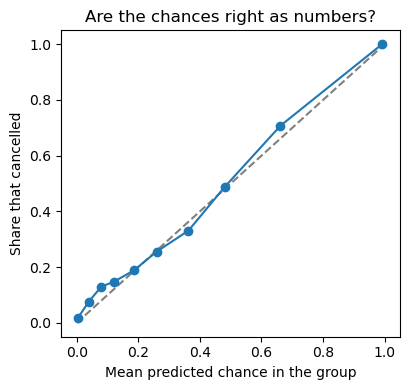

{'version': '2017-01-01', 'trained_on': '78,703 bookings arriving 2015-07-01 to 2016-12-31', 'gate_auc': 0.8549, 'known_limits': ['weaker on bookings without a deposit', 'under-forecasts when the cancellation rate rises', 'too optimistic about the safest bookings']}


In [13]:
tenth = pd.qcut(quarter_table["risk"], 10, labels=False)
calibration = quarter_table.groupby(tenth).agg(predicted=("risk", "mean"),
                                               cancelled=("is_canceled", "mean"))
print(calibration.round(3).T.to_string())

plt.figure(figsize=(4.2, 4))
plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.plot(calibration["predicted"], calibration["cancelled"], marker="o")
plt.xlabel("Mean predicted chance in the group")
plt.ylabel("Share that cancelled")
plt.title("Are the chances right as numbers?")
plt.tight_layout()
plt.savefig(RESULTS / "are_the_chances_right_as_numbers.png", dpi=160, bbox_inches="tight")
plt.show()

full_card = card | {
    "model": "logistic regression (champion)",
    "test_quarter": "January to March 2017, opened once",
    "known_limits": ["weaker on bookings without a deposit",
                     "under-forecasts when the cancellation rate rises",
                     "too optimistic about the safest bookings"],
}
(RESULTS / "model_card.json").write_text(json.dumps(full_card, indent=2), encoding="utf-8")
print({key: full_card[key] for key in ["version", "trained_on", "gate_auc", "known_limits"]})

**What the output shows.** <!-- figure: are_the_chances_right_as_numbers.png | Are the chances right as numbers? | 5.4cm -->
From a predicted 18% upwards the groups sit close to the diagonal. Below that the model is too optimistic: its three safest tenths are predicted to cancel 0.4%, 3.9% and 7.9% of the time and did so 1.8%, 7.6% and 12.9% of the time. That is where most of the shortfall in the count comes from. The card records it, with the other two limits, beside the facts that `train` collected: the version, the training period and the gate AUC of 0.8549.

**Checkpoint: before you move on**

- The travel agent added 0.017 to the logistic regression. The columns written too late lift the first set from 0.8419 to 0.8841, and are not allowed.
- The rule chose the logistic regression: a gap of 0.0020 against a spread of 0.0157.
- Test quarter: AUC 0.855, 4,079 cancellations expected against 4,281; 0.793 without a deposit.
- The safest tenths cancel more often than predicted.

## Part D — Ship it

**Goal.** Run the project as someone else would: train with one command, run the tests, send requests to the web service, and use the page made for the front desk.

*Questions 14–17 · Data: hotel bookings*

### Question 14 — Train with one command

Everything in Part C was done by hand in this notebook. In the project, one command does it: `python booking_project/train.py`. Run it from here exactly as you would in a terminal, read what it reports, and look at what it wrote.

**Read the code.**

- `subprocess.run([...], capture_output=True, text=True)` runs the command and keeps what it printed. `sys.executable` is the Python that runs this notebook, so the script uses the same packages.
- The script reports through Python's `logging`, which writes to the error stream, `result.stderr`. `line.split(" ", 2)[2]` drops the date and the time at the start of each line.
- `result.returncode` is 0 when the command succeeded.
- The run log, `runs.csv`, gains one line per run; the cell prints the last.

In [14]:
command = [sys.executable, "booking_project/train.py", "--models", str(MODELS), "--results", str(RESULTS)]
result = subprocess.run(command, capture_output=True, text=True)
for line in result.stderr.splitlines():
    print(line.split(" ", 2)[2])
print("return code:", result.returncode)

saved_card = json.loads((MODELS / "booking_cancellation_card.json").read_text(encoding="utf-8"))
print("card:", {key: saved_card[key] for key in ["version", "trained_on", "gate_auc"]})
print("last line of the run log:", (RESULTS / "runs.csv").read_text().splitlines()[-1].split(",", 1)[1])

WARNING contract: adults: 12 values outside 0 to 10
WARNING contract: children: 4 blank cells
WARNING contract: market_segment: unexpected values ['Undefined']
WARNING contract: distribution_channel: unexpected values ['Undefined']
WARNING contract: adr: 2 values outside 0 to 1000
INFO read 119,390 bookings, 5 contract warnings
INFO gate: AUC 0.8549 on 14,517 bookings; expected 4,585 cancellations, 5,548 happened
INFO wrote booking_cancellation.joblib, booking_cancellation_card.json and a line in runs.csv (2 seconds)
return code: 0
card: {'version': '2017-01-01', 'trained_on': '78,703 bookings arriving 2015-07-01 to 2016-12-31', 'gate_auc': 0.8549}
last line of the run log: booking_cancellation,2017-01-01,14517,0.8549,0.147,4585,5548


**What the output shows.** The script does what Part C did by hand: five contract warnings, each a decision already taken in Question 3, then the gate, then three files written. The gate is the fourth forward fold: the model fitted before October 2016 scores 0.8549 on the last quarter of 2016 and expects 4,585 cancellations where 5,548 happened, the same under-forecast as everywhere. The time at the end of the last log line depends on the computer. The return code 0 says the run succeeded, and a scheduler that runs this script every month reads exactly that number. The last line of `runs.csv` is this run, with every earlier run above it.

### Question 15 — Run the tests

Before a new version ships, its tests must pass. The project's seven tests check the contract, the features, an unknown category, a floor for the AUC, a direction the hotel relies on, and the service. Run them, then read `booking_project/test_project.py` to see what each one checks.

**Read the code.**

- The test file runs as a plain script and prints one line per test. It can also be run with `pytest`, a tool for running tests, if you have it.
- A test that fails raises an error, the script stops, and the return code is not 0.

In [15]:
command = [sys.executable, "booking_project/test_project.py"]
result = subprocess.run(command, capture_output=True, text=True)
print(result.stdout)
print("return code:", result.returncode)

passed: test_a_new_category_does_not_crash
passed: test_contract_accepts_a_real_booking
passed: test_contract_says_what_is_wrong
passed: test_features_do_not_depend_on_the_batch
passed: test_model_clears_the_floor
passed: test_non_refundable_bookings_score_higher
passed: test_service_answers_and_refuses
7 tests passed

return code: 0


**What the output shows.** All seven tests pass and the return code is 0. Read the test file once: each test is a few lines long, and each guards something that goes wrong in real projects, from a contract that stops reporting a mistake to a feature that is computed differently for one booking than for a table.

### Question 16 — Send requests to the web service

The service of `serve.py` answers one booking at a time. Build it around the champion, and send it requests through Flask's test client, which needs no server: a health check, a good booking, a booking with a mistake, and a request that is not a booking at all. Then read the prediction log it wrote.

**Read the code.**

- `create_app(champion, version, log_path=...)` builds the service. `.test_client()` returns an object whose `get` and `post` send requests straight to it.
- `client.post("/predict", json=booking)` sends the booking as JSON. `.status_code` is 200 for an answer and 400 for a refused request, and `.get_json()` reads the reply.
- The log has one JSON line per answered request. `json.loads` reads it back into a dictionary. The cell prints the names of its fields and two of their values; the time and the milliseconds change on every run.

In [16]:
log_path = RESULTS / "predictions.log"
log_path.unlink(missing_ok=True)                       # start a fresh log on every run
client = create_app(champion, card["version"], log_path=log_path).test_client()

print("health:", client.get("/health").get_json())
for label, sent in [("good booking", booking), ("lead time of -5", {**booking, "lead_time": -5})]:
    reply = client.post("/predict", json=sent)
    print(f"{label}: {reply.status_code} {reply.get_json()}")
reply = client.post("/predict", data="hello")
print(f"not a booking: {reply.status_code} {reply.get_json()}")

logged = [json.loads(line) for line in log_path.read_text(encoding="utf-8").splitlines()]
print("lines in the log:", len(logged), "  fields:", sorted(logged[0]))
print("first line, in part:", {key: logged[0][key] for key in ["model_version", "risk"]})

health: {'model_version': '2017-01-01', 'status': 'ok'}
good booking: 200 {'cancel_probability': 0.0612, 'model_version': '2017-01-01'}
lead time of -5: 400 {'error': 'the booking breaks the contract', 'problems': ['lead_time: -5 is outside 0 to 800']}
not a booking: 400 {'error': 'send one booking as a JSON object'}
lines in the log: 1   fields: ['booking', 'milliseconds', 'model_version', 'risk', 'time']
first line, in part: {'model_version': '2017-01-01', 'risk': 0.0612}


**What the output shows.** The health check names the model version. The good booking gets a 6.1% chance of cancelling. The booking with a negative lead time is refused with status 400 and the reason, and so is a request that is not a booking. Only the answered request reached the log, with five fields: the booking itself, the time, the version, the answer and how long it took. In a real service, that log is what the monitoring of Part E reads.

### Question 17 — Use the page made for the front desk

`app.py` is a one-page Streamlit app. Normally you start it with `streamlit run booking_project/app.py` and use it in a browser. Streamlit can also run it inside a program, which lets you change its fields and read its result here.

**Read the code.**

- `AppTest.from_file(...)` loads the app, and `.run()` runs it once, as a browser would on opening the page.
- `page.metric[0].value` is the text of the page's first result box.
- `page.selectbox(key="deposit_type").select("Non Refund").run()` changes one field and runs the page again, as a click would. Each field has a `key` in `app.py` for this purpose. The changes add up: each starts from the page as the previous one left it.
- `number_input(key="lead_time").set_value(days)` types a number into a field.
- The loop over `logging.root.manager.loggerDict` quietens a warning Streamlit gives when no browser is attached, which is expected here.

In [17]:
import logging
from streamlit.testing.v1 import AppTest
for name in list(logging.root.manager.loggerDict):     # Streamlit warns that no browser is attached,
    if name.startswith("streamlit"):                   # which is expected here: quieten its loggers
        logging.getLogger(name).setLevel(logging.ERROR)

page = AppTest.from_file("booking_project/app.py", default_timeout=120).run()
print("starting values:", page.metric[0].value)
changes = [("deposit_type", "Non Refund"), ("deposit_type", "No Deposit"), ("market_segment", "Groups"),
           ("market_segment", "Online TA")]
for key, value in changes:
    page.selectbox(key=key).select(value).run()
    print(f"{key} = {value}: {page.metric[0].value}")
for days in [0, 30, 120, 365, 600]:
    page.number_input(key="lead_time").set_value(days).run()
    print(f"lead time of {days} days: {page.metric[0].value}")

starting values: 46%
deposit_type = Non Refund: 99%
deposit_type = No Deposit: 46%
market_segment = Groups: 71%
market_segment = Online TA: 46%
lead time of 0 days: 11%
lead time of 30 days: 40%
lead time of 120 days: 49%
lead time of 365 days: 42%
lead time of 600 days: 29%


**What the output shows.** The page opens at 46%. A non-refundable deposit raises that to 99%, and switching back restores 46%, so the page computes from its fields and keeps no hidden state. The Groups segment raises the chance to 71%. The lead time is the interesting field: with everything else as at the start, the chance climbs from 11% for a booking made on the day to 49% for one made 120 days ahead, and then falls, to 42% at a year and 29% at 600 days. Lab 1 found the share cancelled rising all the way to a year. Both can be true, because bookings made far ahead are often groups with non-refundable deposits, which the model accounts for separately. But the shape comes from two columns, the lead time and its logarithm, whose weights pull in opposite directions, and a shape like this deserves a check before customers meet it. A page made for people is often the quickest way to find one.

**Checkpoint: before you move on**

- One command trains, checks, gates and logs: gate AUC 0.8549, return code 0.
- Seven tests pass.
- The service answers a good booking (6.1%), refuses a broken one with its reason, and logs only answers.
- The page shows 46% at the start and 99% with a non-refundable deposit; over the lead time it rises to 49% and falls to 29%.

## Part E — Watch it

**Goal.** Follow the frozen champion through five months of new bookings, read its drift alarms against the right reference, measure the call list that the hotel actually uses, and compare retraining with doing nothing.

*Questions 18–21 · Data: hotel bookings, April to August 2017*

### Question 18 — The monthly report

Run the project's monthly report for April to August 2017. Each line has what could be seen on the first day of the month (new agents, the drift of three inputs and of the predicted chance) and what arrived after it (the count, the AUC, the Brier score). Draw the drift and the AUC side by side.

**Read the code.**

- `monthly_report(champion, bookings, months, reference)` is in `monitor.py`. The reference is the development period, the bookings the champion was trained on.
- `report.filter(like="psi_")` keeps the columns whose names contain `psi_`.
- The left chart draws one line per drift signal and a dashed line at 0.25, the usual threshold for "investigate".

seen on the first day of the month:
         bookings  new_agent_share  psi_lead_time  psi_market_segment  psi_deposit_type  psi_risk
month                                                                                            
2017-04      5661            0.057          0.207               0.075             0.001     0.085
2017-05      6313            0.054          0.161               0.072             0.003     0.058
2017-06      5647            0.059          0.233               0.069             0.005     0.052
2017-07      5313            0.056          0.307               0.353             0.160     0.198
2017-08      4925            0.041          0.225               0.431             0.284     0.340

known after the month:
         expected  cancelled    auc   brier
month                                      
2017-04    2313.0       2463  0.863  0.1462
2017-05    2542.0       2762  0.854  0.1499
2017-06    2281.0       2439  0.834  0.1601
2017-07    1824.0       1984  0.77

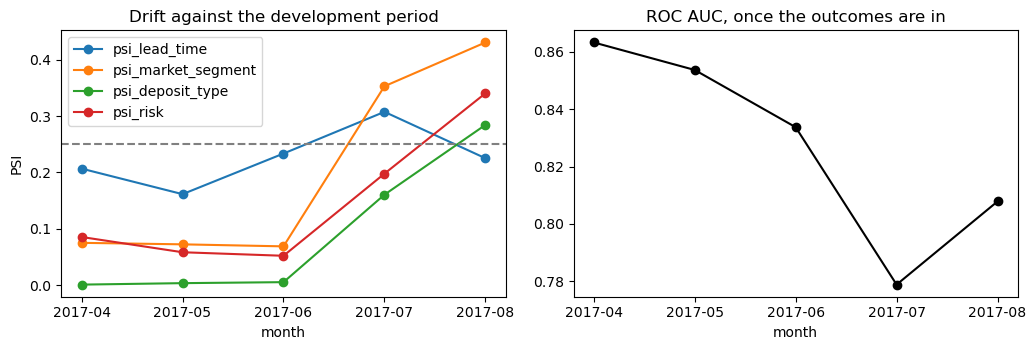

In [18]:
live_months = pd.period_range("2017-04", "2017-08", freq="M")
report = monthly_report(champion, bookings, live_months, bookings[development])
first_day = ["bookings", "new_agent_share", "psi_lead_time", "psi_market_segment", "psi_deposit_type",
             "psi_risk"]
after = ["expected", "cancelled", "auc", "brier"]
print("seen on the first day of the month:")
print(report[first_day].round(3).to_string())
print("\nknown after the month:")
print(report[after].round({"expected": 0, "auc": 3, "brier": 4}).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
report.filter(like="psi_").plot(ax=axes[0], marker="o")
axes[0].axhline(0.25, linestyle="--", color="grey")
axes[0].set_title("Drift against the development period")
axes[0].set_ylabel("PSI")
report["auc"].plot(ax=axes[1], marker="o", color="black")
axes[1].set_title("ROC AUC, once the outcomes are in")
plt.tight_layout()
plt.savefig(RESULTS / "five_months_in_service.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** <!-- figure: five_months_in_service.png | Five months in service | 4.8cm -->
These are the numbers of Chapter 33, now produced by the project's own monitoring code. From April to June the drift signals stay low, apart from the lead time, and the AUC holds between 0.834 and 0.863. In July and August the market segment, the deposit type and the model's own output cross 0.25, and the AUC drops to 0.779 and 0.808. Every month the model expects too few cancellations.

### Question 19 — Compare like with like

The alarms of July and August need an answer before anyone acts on them. Compute the drift of the same columns against two references: the whole development period, and the same month a year earlier. Then compare the two summers on the outcome itself.

**Read the code.**

- `psi(reference, current)` is the function of `monitor.py`. It works on number columns and text columns alike.
- `pd.Period(name) - 12` is the same month a year earlier.
- The second loop scores each summer month with a model trained on every booking before that month, so that both years are judged the same way.

In [19]:
references = {}
for name in ["2017-07", "2017-08"]:
    now, year_ago = bookings[month == name], bookings[month == pd.Period(name) - 12]
    for column in ["market_segment", "deposit_type", "lead_time", "adr"]:
        references[(name, column)] = {
            "against development": psi(bookings.loc[development, column], now[column]),
            "against a year earlier": psi(year_ago[column], now[column])}
print(pd.DataFrame(references).T.round(2).to_string())

summers = {}
for name in ["2016-07", "2016-08", "2017-07", "2017-08"]:
    current = bookings[month == name]
    model, _ = train(bookings, pd.Period(name).start_time)
    no_deposit = (current["deposit_type"] == "No Deposit").to_numpy()
    risk = model.predict_proba(current[project.FEATURES])[:, 1]
    summers[name] = {"auc": roc_auc_score(current["is_canceled"], risk),
                     "share_without_deposit": no_deposit.mean(),
                     "cancelled_without_deposit": current.loc[no_deposit, "is_canceled"].mean()}
print(pd.DataFrame(summers).T.round(3).to_string())

                        against development  against a year earlier
2017-07 market_segment                 0.35                    0.03
        deposit_type                   0.16                    0.03
        lead_time                      0.31                    0.11
        adr                            1.51                    0.24
2017-08 market_segment                 0.43                    0.01
        deposit_type                   0.28                    0.05
        lead_time                      0.23                    0.03
        adr                            2.04                    0.20


           auc  share_without_deposit  cancelled_without_deposit
2016-07  0.857                  0.939                      0.285
2016-08  0.846                  0.948                      0.327
2017-07  0.797                  0.967                      0.353
2017-08  0.819                  0.985                      0.359


**What the output shows.** Against the same month a year earlier the alarms fall silent: the segment's index drops from 0.35 to 0.03 in July and from 0.43 to 0.01 in August. Summer simply looks like this, with few groups and few non-refundable deals. The outcomes tell a different story. Part of the fall in AUC is the mix: bookings without a deposit, the hard ones, rose from 93.9% to 96.7% of July. The rest is the guests: among bookings without a deposit, 35.3% were cancelled in July 2017 against 28.5% in July 2016. No input alarm could have seen that.

### Question 20 — Measure the call list

The hotel uses the model in two ways, and so far only the count and the AUC have been measured. The call list is the other use: each month, staff call the 300 riskiest bookings without a deposit to ask whether the guests are still coming. What matters is how many of those 300 would have cancelled. Compare the champion, the challenger and a simple rule (call the bookings made furthest ahead).

**Read the code.**

- Bookings with a non-refundable deposit are left out: the hotel keeps their money whether they cancel or not, so there is no point calling.
- `np.argsort(risk)[::-1][:calls]` gives the positions of the 300 highest chances, highest first.
- `cancelled[top].sum()` counts the cancellations among them: the calls that reached a guest who was going to cancel.
- `current["is_canceled"].mean() * calls` is what 300 calls at random would find on average.

In [20]:
calls = 300
call_list = []
for name in live_months:
    current = bookings[(month == name) & (bookings["deposit_type"] == "No Deposit")]
    cancelled = current["is_canceled"].to_numpy()
    row = {"month": str(name), "bookings": len(current), "at_random": cancelled.mean() * calls}
    for label, model in [("champion", champion), ("challenger", challenger)]:
        risk = model.predict_proba(current[project.FEATURES])[:, 1]
        top = np.argsort(risk)[::-1][:calls]
        row[label] = int(cancelled[top].sum())
    furthest = np.argsort(current["lead_time"].to_numpy())[::-1][:calls]
    row["furthest_ahead"] = int(cancelled[furthest].sum())
    call_list.append(row)
call_list = pd.DataFrame(call_list).set_index("month")
print(call_list.round(0).to_string())
print("in total:", call_list[["champion", "challenger", "furthest_ahead"]].sum().to_dict(),
      " at random:", round(call_list["at_random"].sum()))

         bookings  at_random  champion  challenger  furthest_ahead
month                                                             
2017-04      4863      103.0       244         249             143
2017-05      5341      101.0       222         230             136
2017-06      4816      100.0       217         212              80
2017-07      5140      106.0       238         224              76
2017-08      4853      108.0       251         238             115
in total: {'champion': 1172, 'challenger': 1153, 'furthest_ahead': 550}  at random: 517


**What the output shows.** Calls at random would reach about 100 future cancellations a month, 517 in five months, and calling the bookings made furthest ahead does little better, 550. The champion's 300 calls reach 217 to 251 guests a month who were going to cancel: 1,172 in all. The surprise is the challenger. It has the higher AUC in every month, yet its calls reach fewer future cancellations, 1,153, and fewer in three months of five. The AUC judges the order of all 5,000 or so bookings without a deposit, and the call list uses only the top 300. Before promoting the challenger, as Chapter 33's rule would, check it on the measure each use depends on: it may be better for the count and no better for the calls.

### Question 21 — Retrain on the first day of every month

Instead of leaving the champion frozen, retrain it on the first day of each month with every booking that has arrived by then. Accept a retrained model only if its gate AUC is at least 0.80, the floor agreed with the hotel. Compare the count and the AUC with the frozen champion.

**Read the code.**

- `train(bookings, name.start_time)` fits on every booking before the first day of the month and returns the gate AUC in its facts.
- `facts["gate_auc"] >= 0.80` is the acceptance test. A model that failed it would not replace the one in service, and the frozen champion would keep answering.
- In the table, `frozen` and `retrained` are the numbers of cancellations each policy expected, and the last two columns are their AUCs. The last two lines add up the five months.

In [21]:
retraining = []
for name in live_months:
    current = bookings[month == name]
    model, facts = train(bookings, name.start_time)
    accepted = facts["gate_auc"] >= 0.80
    in_service = model if accepted else champion
    risk = in_service.predict_proba(current[project.FEATURES])[:, 1]
    frozen = champion.predict_proba(current[project.FEATURES])[:, 1]
    retraining.append({"month": str(name), "gate": facts["gate_auc"], "accepted": accepted,
                       "cancelled": int(current["is_canceled"].sum()),
                       "frozen": frozen.sum(), "retrained": risk.sum(),
                       "auc_frozen": roc_auc_score(current["is_canceled"], frozen),
                       "auc_retrained": roc_auc_score(current["is_canceled"], risk)})
retraining = pd.DataFrame(retraining).set_index("month")
print(retraining.round({"frozen": 0, "retrained": 0, "auc_frozen": 3, "auc_retrained": 3}).to_string())
totals = retraining[["cancelled", "frozen", "retrained"]].sum()
print("over five months:", totals.round(0).astype(int).to_dict())

           gate  accepted  cancelled  frozen  retrained  auc_frozen  auc_retrained
month                                                                             
2017-04  0.8553      True       2463  2313.0     2307.0       0.863          0.868
2017-05  0.8603      True       2762  2542.0     2561.0       0.854          0.859
2017-06  0.8593      True       2439  2281.0     2373.0       0.834          0.839
2017-07  0.8535      True       1984  1824.0     1960.0       0.779          0.797
2017-08  0.8393      True       1816  1565.0     1675.0       0.808          0.819
over five months: {'cancelled': 11464, 'frozen': 10526, 'retrained': 10876}


**What the output shows.** Every retrained model passed its gate, with AUCs from 0.8393 to 0.8603, all above the 0.80 floor. Retraining raised the AUC in every month, most in July (0.797 against 0.779), and the forecast for the five months rose from 10,526 to 10,876 cancellations, against 11,464 that happened: 350 of the 938 missing cancellations recovered.

**Checkpoint: before you move on**

- The July and August alarms vanish against the same months of 2016.
- Without a deposit, 35.3% were cancelled in July 2017 against 28.5% a year earlier.
- Calls: the champion reached 1,172 future cancellations, the challenger 1,153, calls at random 517.
- Retraining: 10,876 cancellations expected against 11,464, up from 10,526.

## Finish — Save the evidence, then try it yourself

**Goal.** Write the results folder, then correct the monthly count yourself before reading one worked solution.

*Questions 22–24*

### Question 22 — Save the evidence

Write the tables behind this lab's findings to the results folder. The experiment log, the model card, the run log and the prediction log were written earlier. These files are regenerated on every run, so do not edit them by hand, with one exception: `runs.csv` keeps one line for every run, which is its purpose.

**Read the code.**

- Each `to_csv` writes one table. `rename_axis` names the index column.
- `RESULTS.iterdir()` lists the folder, and `sorted` puts the names in order.

In [22]:
by_quarter.rename_axis("quarter").to_csv(RESULTS / "cancellations_by_quarter.csv")
groups.round(4).to_csv(RESULTS / "test_quarter_by_group.csv")
calibration.round(4).rename_axis("tenth").to_csv(RESULTS / "test_quarter_calibration.csv")
report.round(4).to_csv(RESULTS / "monthly_report.csv")
call_list.round(1).to_csv(RESULTS / "call_list.csv")
retraining.round(4).to_csv(RESULTS / "retraining.csv")
print("Saved:", sorted(p.name for p in RESULTS.iterdir()))

Saved: ['are_the_chances_right_as_numbers.png', 'call_list.csv', 'cancellations_by_month_of_arrival.png', 'cancellations_by_quarter.csv', 'experiment_log.csv', 'five_months_in_service.png', 'model_card.json', 'monthly_report.csv', 'predictions.log', 'retraining.csv', 'runs.csv', 'test_quarter_by_group.csv', 'test_quarter_calibration.csv']


**What the output shows.** Thirteen files: three figures, the tables of this lab, the experiment log, the model card, the prediction log and the run log. `call_list.csv` and `retraining.csv` are the two to show the revenue manager.

## Try it yourself

Every month the forecast of the number of cancellations came out short, and retraining narrowed the gap without closing it. A simpler correction is available on the first day of each month: the previous month's outcomes are known by then. Multiply each month's expected count by the ratio of cancelled to expected in the month before, and compare the corrected forecasts of April to August with the uncorrected ones. Use the frozen champion, and remember that April's correction comes from March, the last month of the test quarter.

Attempt it in the cell below before reading the solution.

### Question 23 — Try it yourself

In [23]:
# Your work here

### One solution

The ratio of the month before, applied to the expected count of each month, with the frozen champion.

### Question 24 — One solution

The ratio of the month before, applied to the expected count of each month, with the frozen champion.

**Read the code.**

- `expected[name]` is the frozen champion's sum of predicted chances for a month, and `actual[name]` the number that cancelled.
- `name - 1` is the month before, a `Period` minus one month.
- The error of each forecast is the forecast divided by the truth, minus one: negative means too few.

In [24]:
months = pd.period_range("2017-03", "2017-08", freq="M")
expected, actual = {}, {}
for name in months:
    current = bookings[month == name]
    expected[name] = champion.predict_proba(current[project.FEATURES])[:, 1].sum()
    actual[name] = int(current["is_canceled"].sum())

rows = []
for name in months[1:]:
    ratio = actual[name - 1] / expected[name - 1]                  # known on the first day of the month
    rows.append({"month": str(name), "cancelled": actual[name], "model": expected[name],
                 "ratio_used": ratio, "corrected": expected[name] * ratio})
corrected = pd.DataFrame(rows).set_index("month")
corrected["model_error"] = corrected["model"] / corrected["cancelled"] - 1
corrected["corrected_error"] = corrected["corrected"] / corrected["cancelled"] - 1
print(corrected.round({"model": 0, "ratio_used": 3, "corrected": 0, "model_error": 3,
                       "corrected_error": 3}).to_string())
total = corrected[["cancelled", "model", "corrected"]].sum()
print(f"over five months: {total['cancelled']:,.0f} cancelled, model {total['model']:,.0f}"
      f" ({total['model'] / total['cancelled'] - 1:.1%}), corrected {total['corrected']:,.0f}"
      f" ({total['corrected'] / total['cancelled'] - 1:.1%})")

         cancelled   model  ratio_used  corrected  model_error  corrected_error
month                                                                          
2017-04       2463  2313.0       0.986     2281.0       -0.061           -0.074
2017-05       2762  2542.0       1.065     2707.0       -0.080           -0.020
2017-06       2439  2281.0       1.086     2478.0       -0.065            0.016
2017-07       1984  1824.0       1.069     1950.0       -0.081           -0.017
2017-08       1816  1565.0       1.088     1702.0       -0.138           -0.063
over five months: 11,464 cancelled, model 10,526 (-8.2%), corrected 11,119 (-3.0%)


**What it shows.** The correction uses only what is known on the first day of each month, and it works. Over the five months the corrected forecast is short by 3.0%, against 8.2% for the model alone and 5.1% for monthly retraining in Question 21, and it is better in four months of five. April is the exception: March's ratio was below one, 0.986, so the correction pushed April the wrong way. A correction like this is a second, very small model on top of the first, and it needs the same care. It is fitted on a single month, so it is noisy, and it should be checked on new months before it is trusted.